# h02 — MS lesions and Baló rings: where do CD45-bright lymphocytes, vimentin and neuropil sit?

h01 showed that in human tissue the boundary channel carries CD45 on lymphocytes and the αSMA/vimentin channel
follows *VIM*. There are no lesion annotations, so lesions are mapped from the RNA itself:
1. **Maps** (25 µm bins): myelin RNA (*MBP*, *MOBP*, *MOG*, *MAG*, *OPALIN* transcripts, in or out of cells) as a
   share of all transcripts = where myelin is lost; neuron density = grey matter; myeloid cells (SPP1+ activated and
   other), lymphocytes with the CD45-bright ones marked; astrocyte vimentin; ATP1A1 neuropil (cell territory).
2. **Zones:** white matter split by myelin RNA share relative to the section's own well-myelinated white matter
   (demyelinated < 0.35, partial 0.35–0.7, myelinated > 0.7); grey matter (high neuron density) and the out-of-focus
   holes (no transcripts) left out.
3. **Per section, demyelinated vs myelinated white matter:** CD45-bright lymphocytes, myeloid cells, astrocyte
   vimentin, ATP1A1 neuropil. One donor per section, so these are descriptions of each section, not tests across
   patients.
4. **Baló:** do the stains alternate with the myelin rings? Profiles along the ring pattern and maps side by side.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
import yaml
from scipy import ndimage as ndi

from beyondboundaries import plotting
from beyondboundaries.io import XeniumBundle, find_bundles

plotting.style()
SRC = "human/notebooks/h02_lesions_and_rings.ipynb"
OUT = ROOT / "human" / "results" / "h02_lesions_and_rings"
OUT.mkdir(parents=True, exist_ok=True)
CFG = yaml.safe_load(open(ROOT / "human" / "config.yaml"))
SAMPLES = ["S07-256", "S13-019", "Balo-1", "Balo-2"]
MYELIN = ["MBP", "MOBP", "MOG", "MAG", "OPALIN"]
BIN = 25.0  # µm
LYMPH, MYE, MYE_A = "Lymphocyte (T/B/plasma)", "Myeloid", "Myeloid (SPP1+ activated)"

In [2]:
a = ad.read_h5ad(CFG["annotation"]["h5ad"], backed="r")
ct = pd.read_parquet(ROOT / "human" / "data" / "cell_types.parquet")
cnt = a[:, ["PTPRC"]].to_memory().layers["counts"]
ct["PTPRC"] = np.asarray(cnt.todense()).ravel() if hasattr(cnt, "todense") else np.asarray(cnt).ravel()
a.file.close()
bundles = find_bundles(CFG)
sec_of = {sid.split("_")[1]: sid for sid in bundles}
feats = []
for smp, sid in sec_of.items():
    f = pd.read_parquet(ROOT / CFG["features_dir"] / f"{sid}.parquet")
    if "cell_id" not in f.columns:
        f = f.reset_index()
    f = f[["cell_id", "bnd_rim_mean", "bnd_ring_mean", "bnd_terr_mean", "smavim_cell_mean"]].assign(sample_id=smp)
    feats.append(f)
d = ct.reset_index().merge(pd.concat(feats), on=["sample_id", "cell_id"], how="inner").set_index("index")
d = d[d.cell_type != "low quality"]
d["bnd_contrast"] = np.log(d.bnd_rim_mean.clip(lower=1) / d.bnd_ring_mean.clip(lower=1))
g = d.groupby("sample_id").smavim_cell_mean
d["vim_z"] = (d.smavim_cell_mean - g.transform("median")) / (
    (d.smavim_cell_mean - g.transform("median")).abs().groupby(d.sample_id).transform("median") * 1.4826)
d["atp_rel"] = d.bnd_terr_mean / d.groupby("sample_id").bnd_terr_mean.transform("median")
# CD45-bright lymphocyte: membrane contrast above the 95th percentile of the section's oligodendrocytes
thr = d[d.cell_type == "Oligodendrocyte"].groupby("sample_id").bnd_contrast.quantile(0.95)
d["cd45_bright"] = (d.cell_type == LYMPH) & (d.bnd_contrast > d.sample_id.map(thr))
print("CD45-bright share of lymphocytes:", d[d.cell_type == LYMPH].groupby("sample_id").cd45_bright.mean().round(2).to_dict())

CD45-bright share of lymphocytes: {'Balo-1': 0.84, 'Balo-2': 0.79, 'S07-256': 0.59, 'S13-019': 0.55}


**Transcript maps.** All decoded transcripts (qv ≥ 20) and the myelin genes, binned at 25 µm.

In [3]:
def grid_shape(smp):
    b = XeniumBundle(bundles[sec_of[smp]])
    H, W = b.shape
    return int(np.ceil(H * b.pixel_size / BIN)), int(np.ceil(W * b.pixel_size / BIN))


TX = {}
for smp in SAMPLES:
    shp = grid_shape(smp)
    allc, myel = np.zeros(shp), np.zeros(shp)
    f = pq.ParquetFile(bundles[sec_of[smp]] / "transcripts.parquet")
    for i in range(f.num_row_groups):
        t = f.read_row_group(i, columns=["feature_name", "x_location", "y_location", "qv", "is_gene"])
        t = t.filter(pc.and_(pc.greater_equal(t["qv"], 20), t["is_gene"]))
        iy = np.clip((t["y_location"].to_numpy() / BIN).astype(int), 0, shp[0] - 1)
        ix = np.clip((t["x_location"].to_numpy() / BIN).astype(int), 0, shp[1] - 1)
        np.add.at(allc, (iy, ix), 1)
        m = pc.is_in(t["feature_name"], value_set=pa.array(MYELIN)).to_numpy(zero_copy_only=False)
        np.add.at(myel, (iy[m], ix[m]), 1)
    TX[smp] = dict(all=allc, myelin=myel)
    print(smp, shp, int(allc.sum()), int(myel.sum()))


def cell_grid(smp, mask=None, val=None, stat="sum"):
    shp = TX[smp]["all"].shape
    s = d[(d.sample_id == smp) & (mask if mask is not None else True)]
    iy = np.clip((s.y_centroid / BIN).astype(int), 0, shp[0] - 1)
    ix = np.clip((s.x_centroid / BIN).astype(int), 0, shp[1] - 1)
    out = np.zeros(shp)
    if val is None:
        np.add.at(out, (iy, ix), 1)
        return out
    v = s[val].to_numpy()
    ok = np.isfinite(v)
    num, den = np.zeros(shp), np.zeros(shp)
    np.add.at(num, (iy[ok], ix[ok]), v[ok])
    np.add.at(den, (iy[ok], ix[ok]), 1)
    return num, den

S07-256 (434, 387) 118441884 4664509


S13-019 (405, 411) 130191244 3358924


Balo-1 (290, 435) 32464249 288755


Balo-2 (290, 387) 28706863 830096


**Zones.** Tissue = bins with transcripts (holes and out-of-focus areas drop out). **Meninges / roots** = bins where
fibroblasts + Schwann cells make up > 30 % of cells (smoothed). **Subpial rim** = the first 100 µm inside the outer
tissue edge (kept apart: subpial demyelination is real in MS, but meninges dilute the myelin RNA there). **Grey
matter** = smoothed neuron share > 0.05, islands < 0.05 mm² dropped (check against the neuron map). The remaining
deep white matter is graded by smoothed myelin RNA share ÷ its 90th percentile in the section's deep white matter.

In [4]:
Z = {}
for smp in SAMPLES:
    allc, myel = TX[smp]["all"], TX[smp]["myelin"]
    sm = lambda x, s=2: ndi.gaussian_filter(x, s)
    tissue = sm(allc, 1) > 20
    cells_all = cell_grid(smp)
    neur = cell_grid(smp, d.cell_type.str.startswith("Neuron"))
    neur_share = sm(neur, 4) / np.maximum(sm(cells_all, 4), 1e-3)
    gm = tissue & (neur_share > 0.05)
    lab_, n_ = ndi.label(gm)
    if n_:
        sizes = ndi.sum(gm, lab_, range(1, n_ + 1)) * BIN ** 2 / 1e6
        gm = np.isin(lab_, np.flatnonzero(sizes >= 0.05) + 1)
    men = cell_grid(smp, d.cell_type.isin(["Fibroblast", "Schwann"]))
    men = tissue & (sm(men, 2) / np.maximum(sm(cells_all, 2), 1e-3) > 0.3) & ~gm
    filled = ndi.binary_fill_holes(ndi.binary_closing(tissue, iterations=3))
    edge_um = ndi.distance_transform_edt(filled) * BIN
    rim = tissue & (edge_um <= 100) & ~gm & ~men
    share = sm(myel) / np.maximum(sm(allc), 1)
    wm = tissue & ~gm & ~men & ~rim
    rel = share / np.percentile(share[wm], 90) if wm.any() else share * np.nan
    zone = np.full(allc.shape, "", dtype=object)
    zone[tissue] = "tissue"
    zone[gm] = "grey matter"
    zone[men] = "meninges / roots"
    zone[rim] = "subpial rim"
    zone[wm & (rel < 0.35)] = "demyelinated"
    zone[wm & (rel >= 0.35) & (rel < 0.7)] = "partial"
    zone[wm & (rel >= 0.7)] = "myelinated"
    rim_rel = share / np.percentile(share[wm], 90) if wm.any() else share * np.nan
    Z[smp] = dict(zone=zone, rel=rel, neur_share=neur_share, tissue=tissue, rim_rel=rim_rel, rim=rim)
    vc = pd.Series(zone[tissue]).value_counts()
    print(smp, (vc * BIN ** 2 / 1e6).round(2).to_dict(), "mm²")

S07-256 {'partial': 17.28, 'myelinated': 14.98, 'meninges / roots': 13.6, 'grey matter': 13.18, 'demyelinated': 11.74, 'subpial rim': 0.79} mm²


S13-019 {'myelinated': 23.41, 'partial': 9.92, 'meninges / roots': 5.68, 'demyelinated': 4.5, 'grey matter': 4.4, 'subpial rim': 1.74} mm²


Balo-1 {'grey matter': 18.23, 'subpial rim': 1.57, 'meninges / roots': 0.62, 'demyelinated': 0.42, 'myelinated': 0.07, 'partial': 0.06} mm²


Balo-2 {'grey matter': 16.27, 'myelinated': 3.72, 'partial': 1.28, 'subpial rim': 1.08, 'demyelinated': 0.58, 'meninges / roots': 0.01} mm²


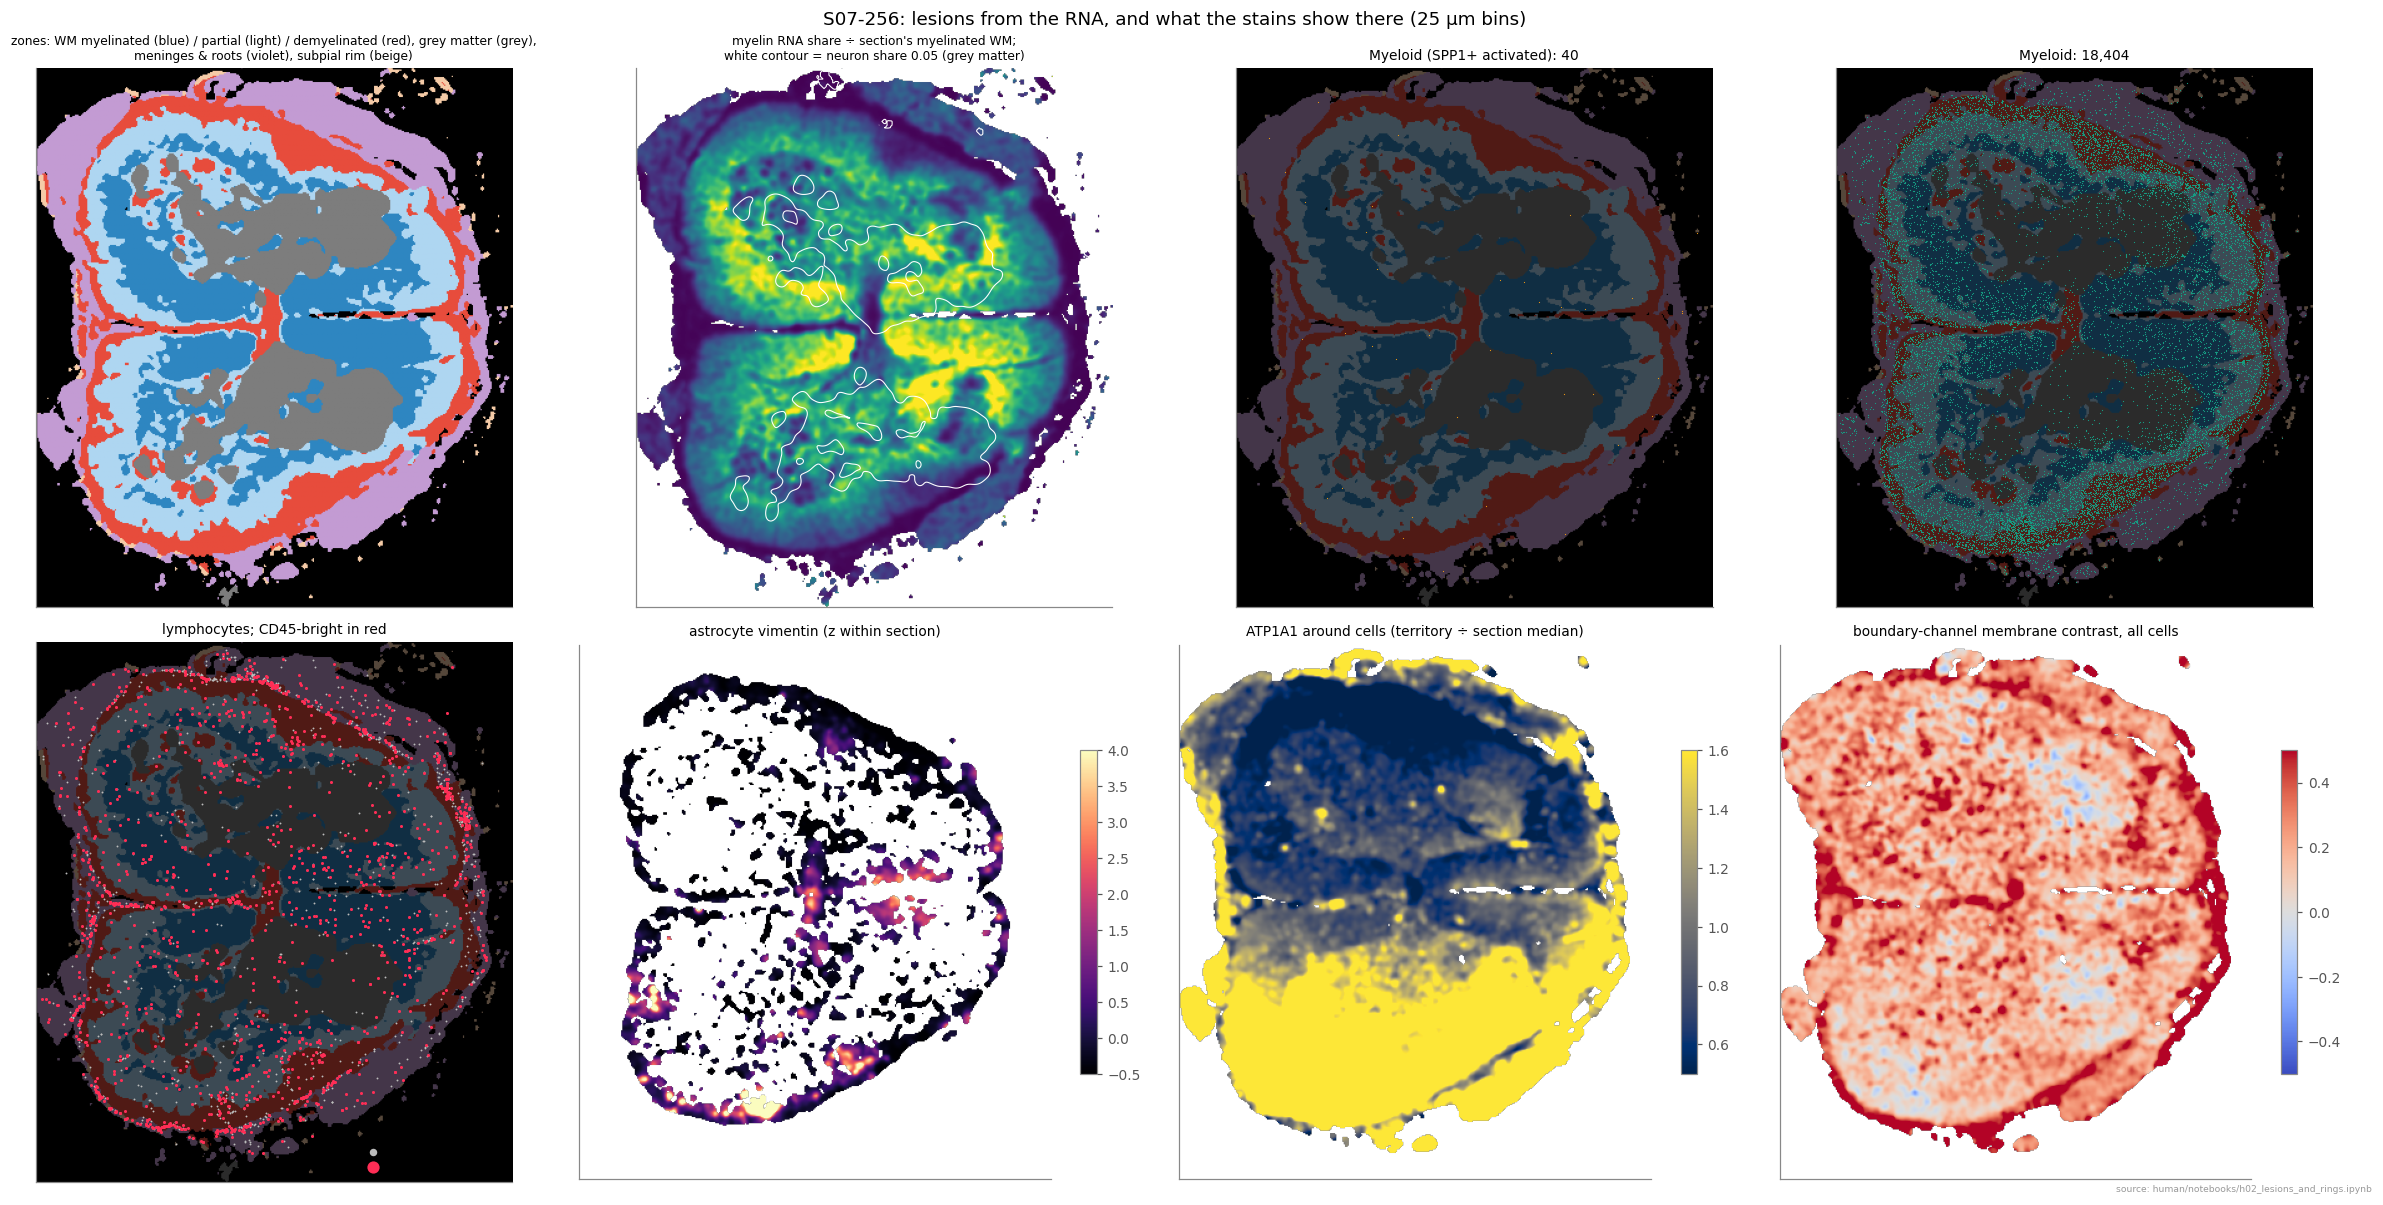

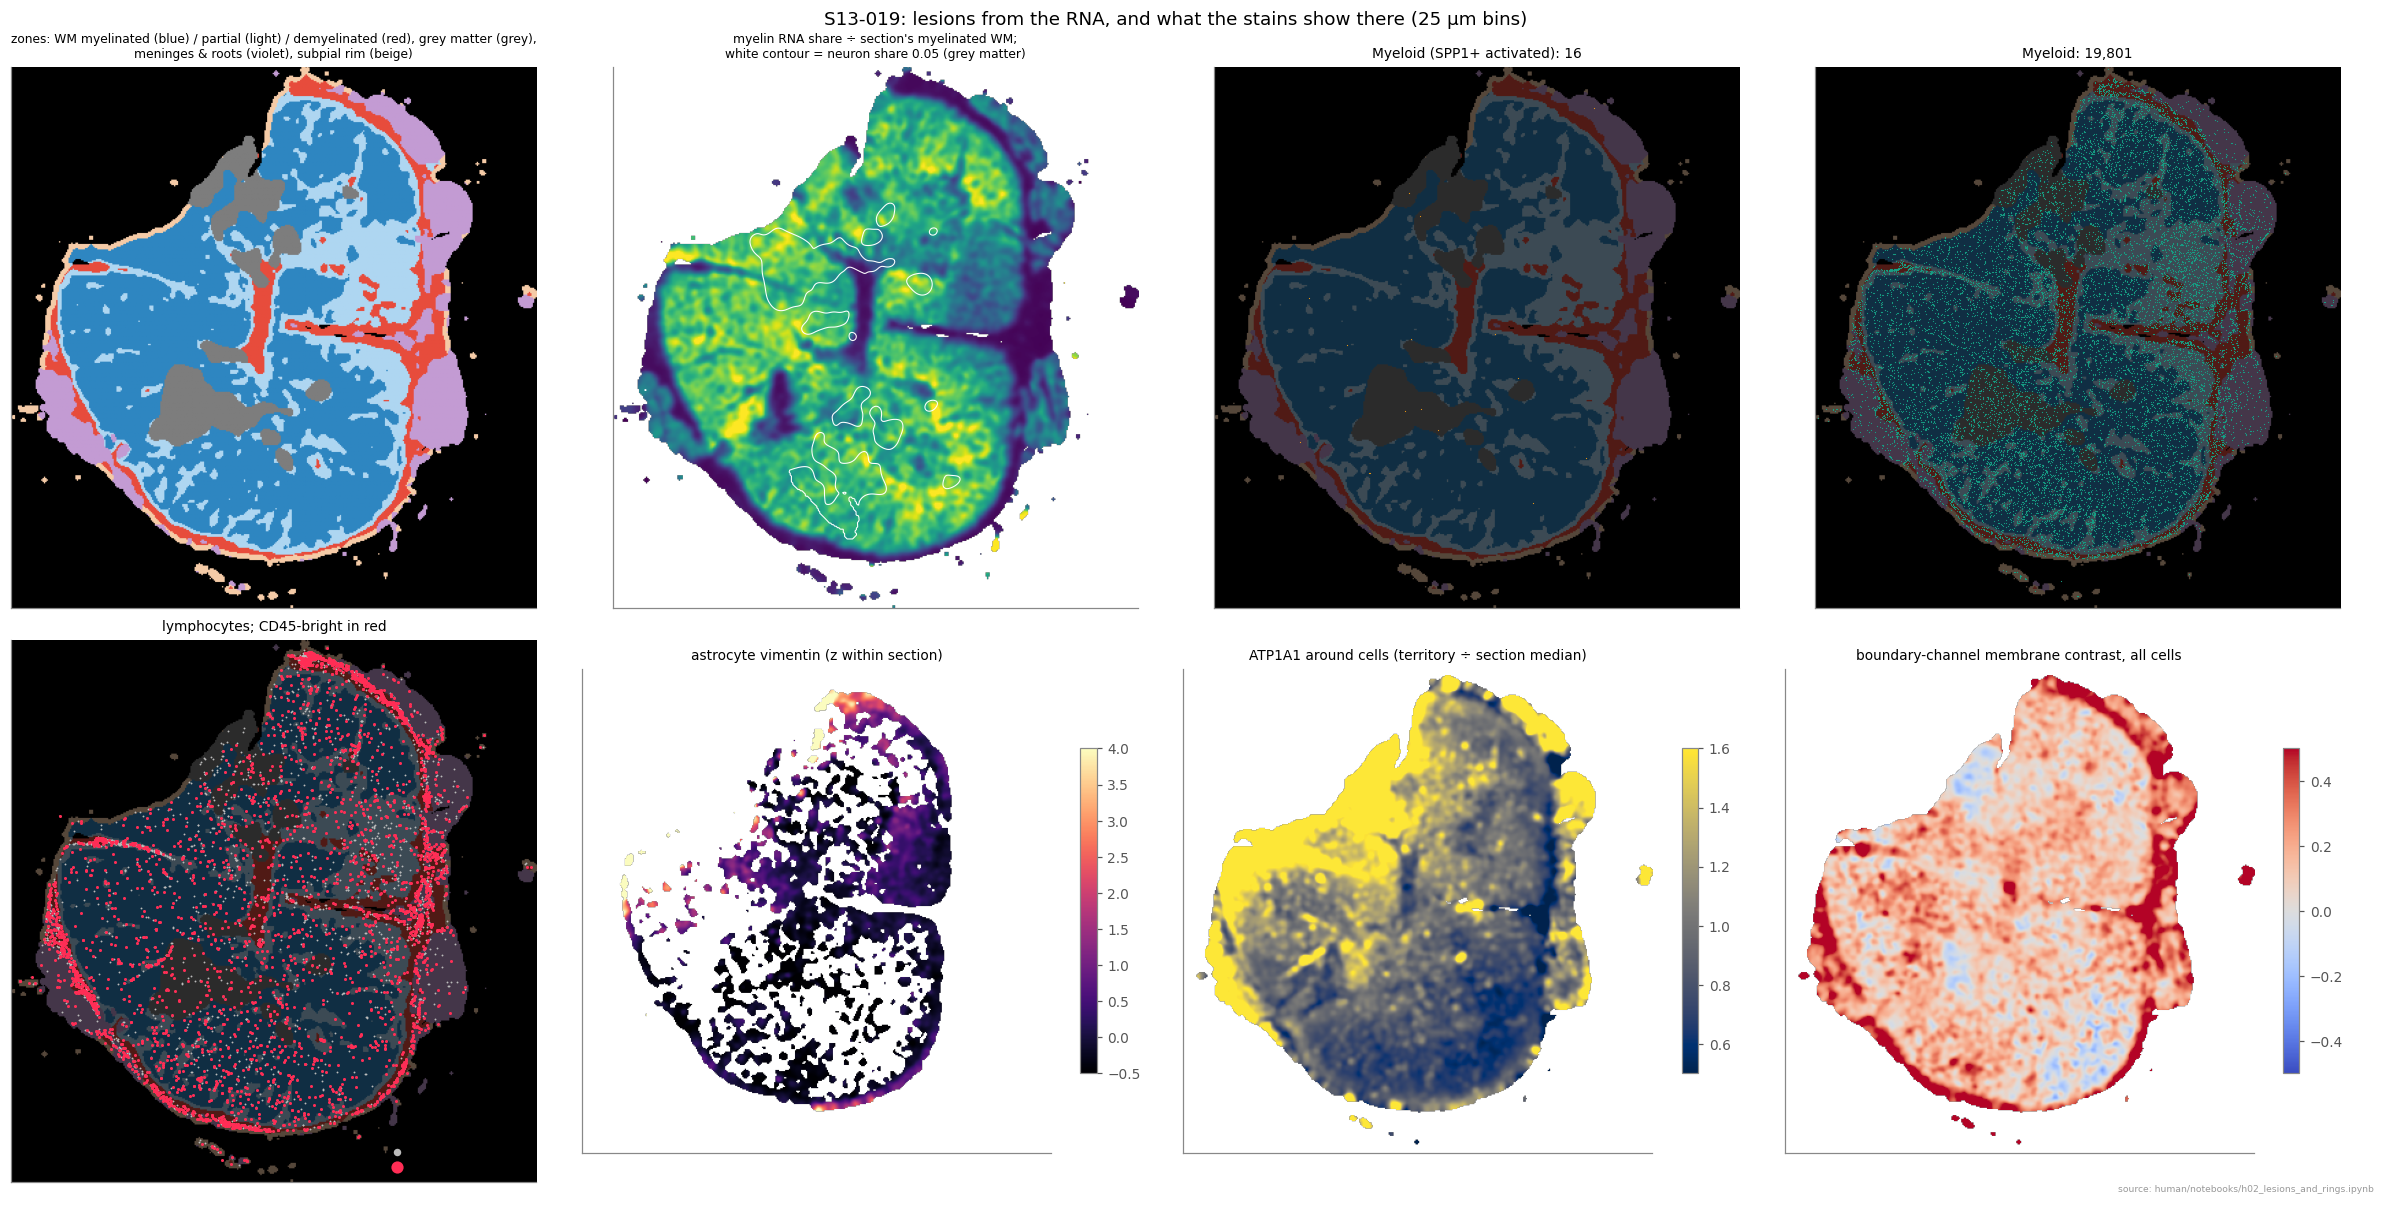

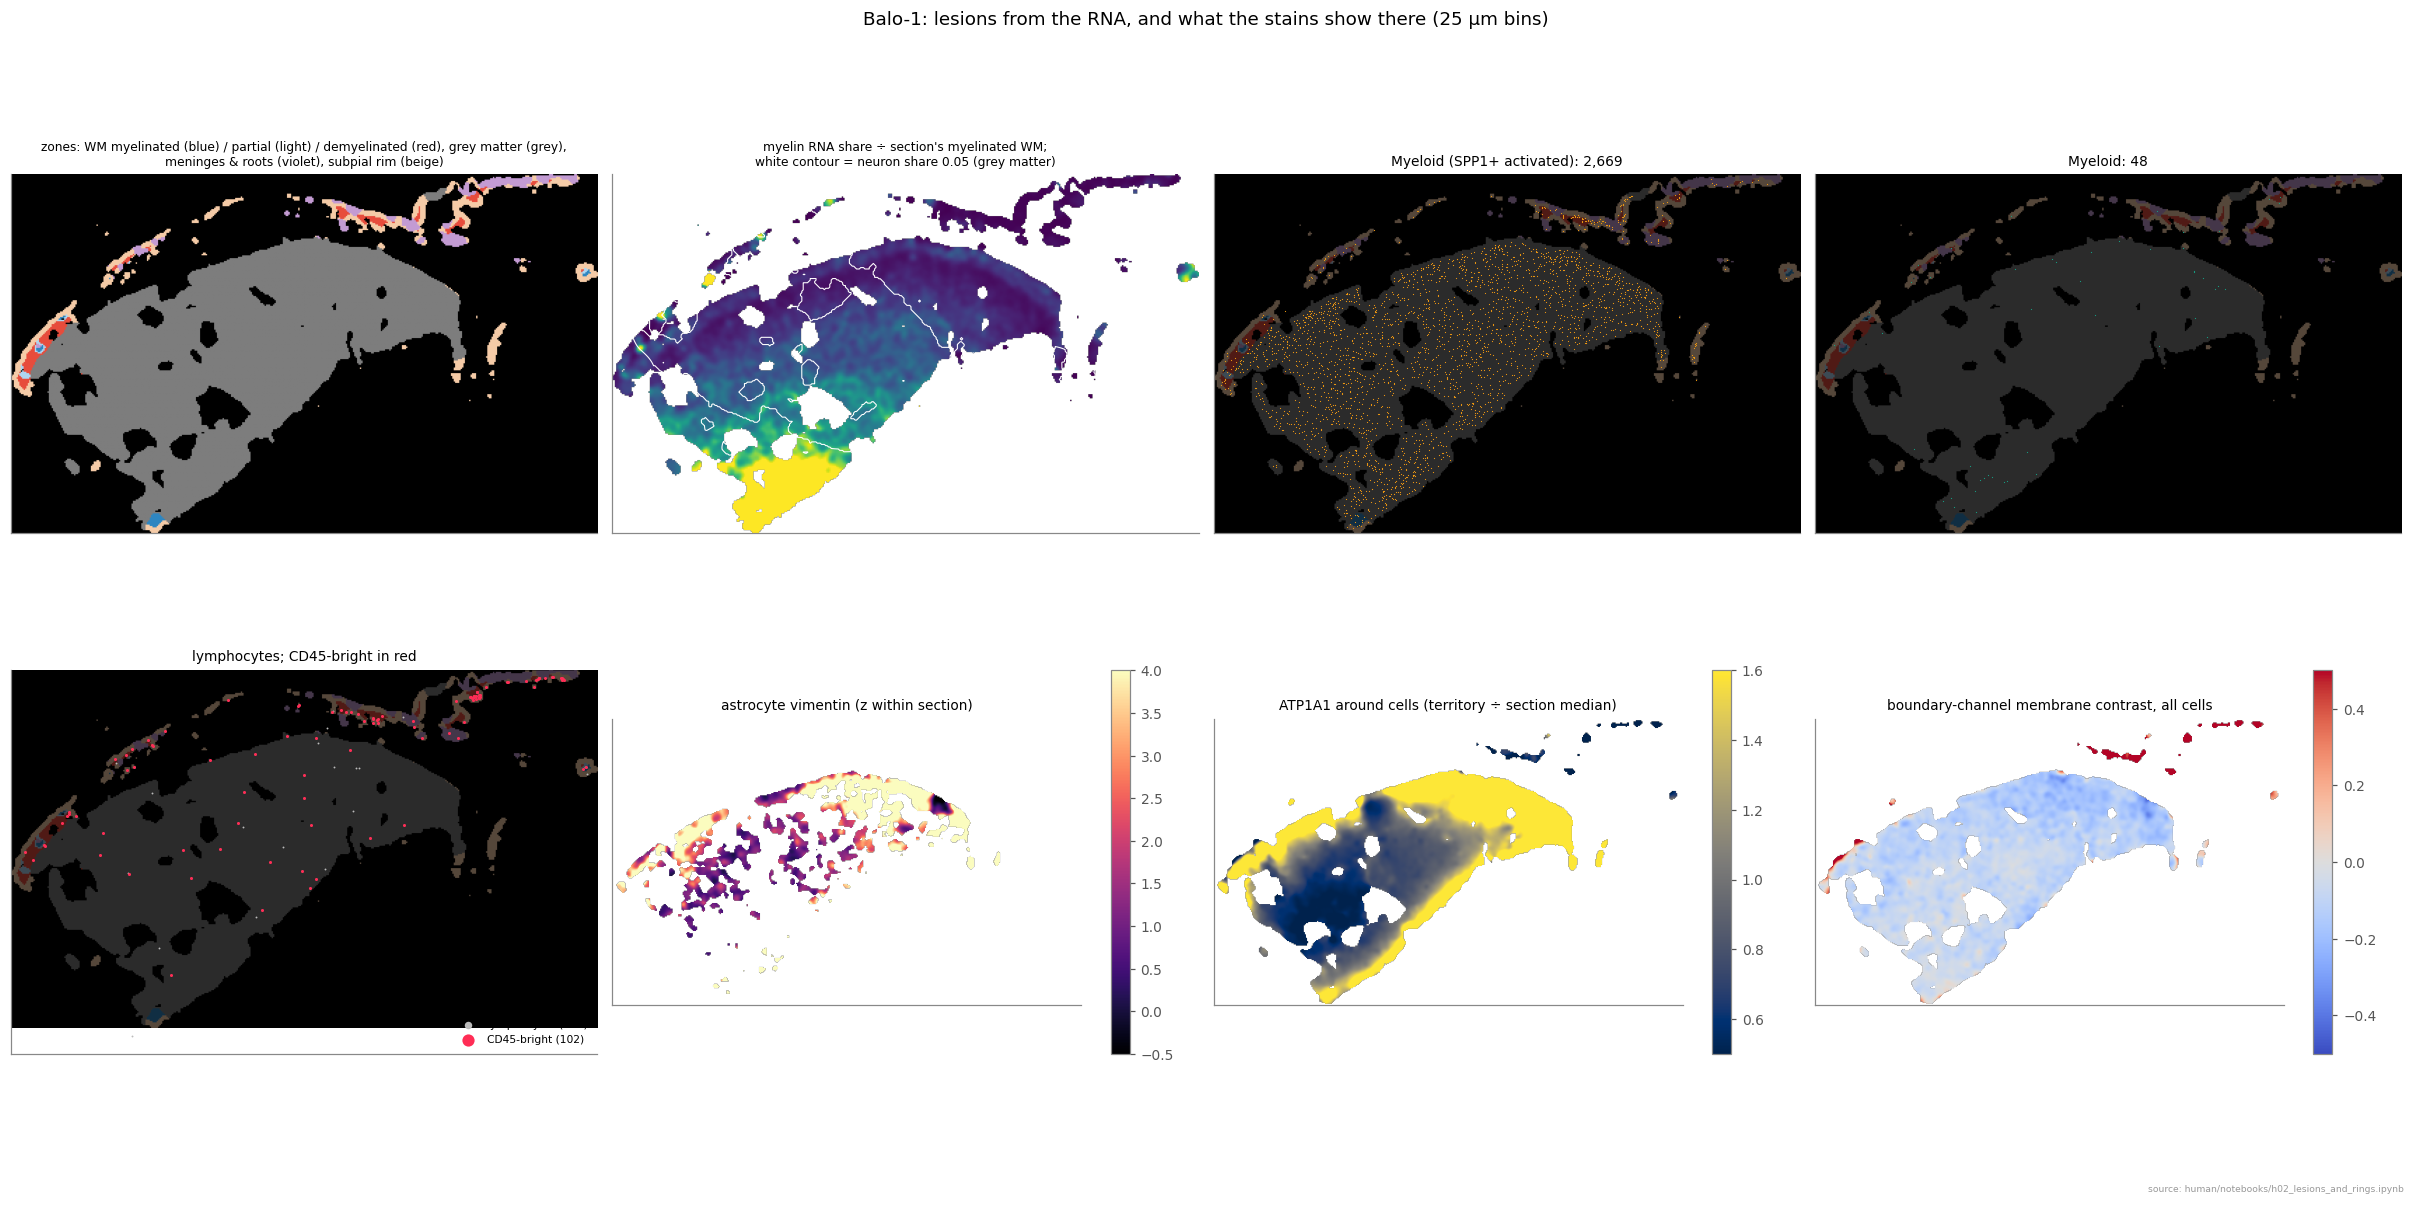

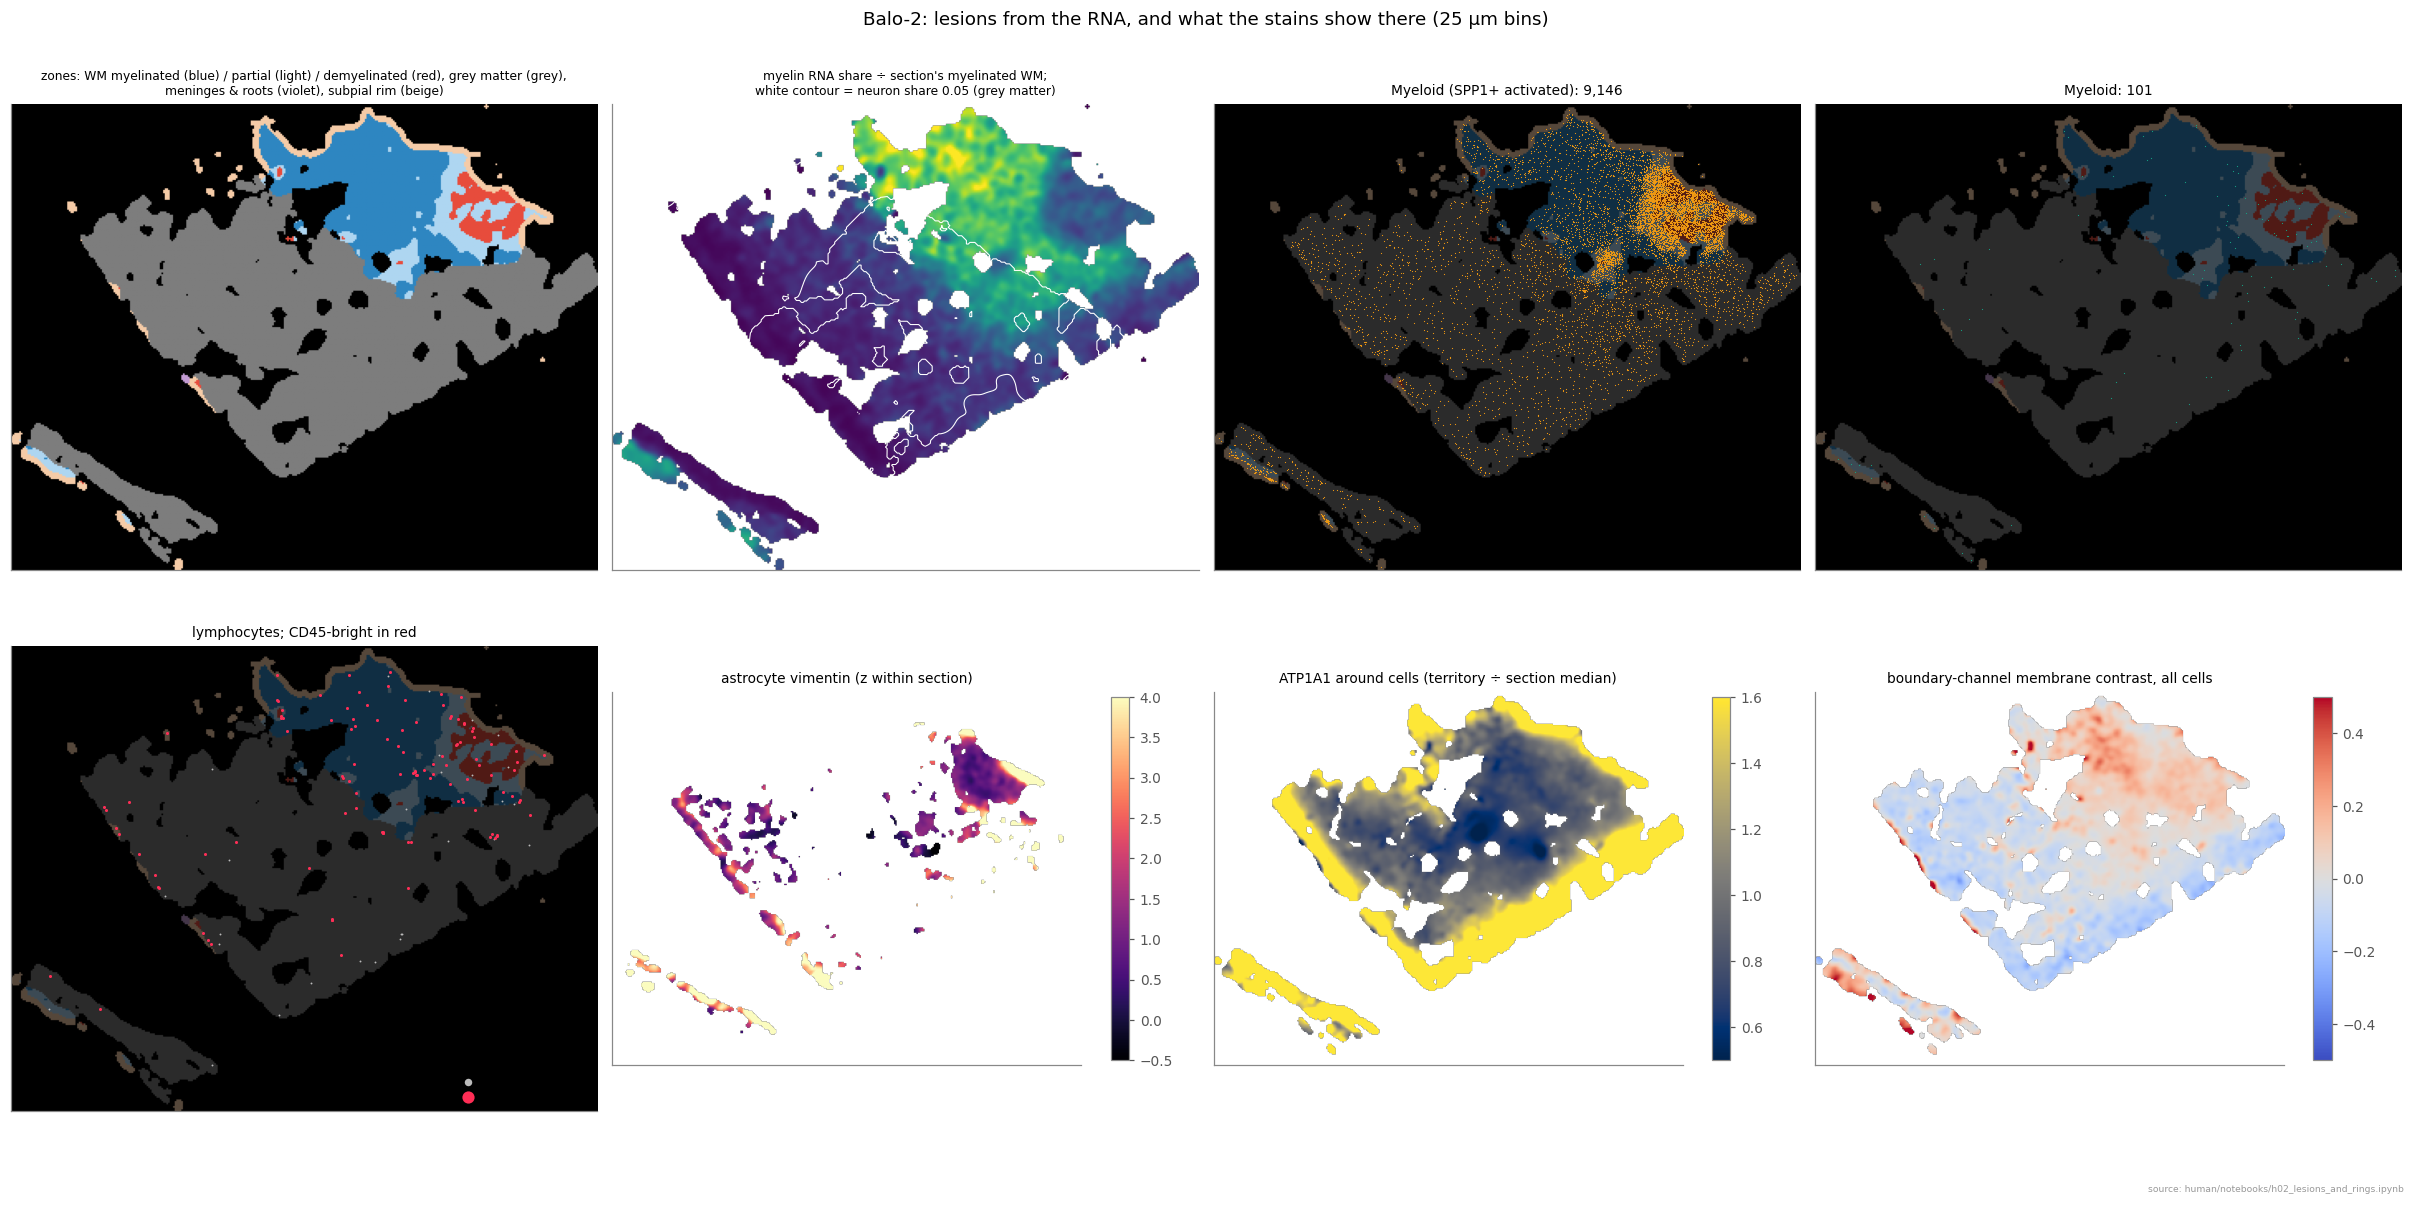

In [5]:
ZCOLS = {"myelinated": "#2e86c1", "partial": "#aed6f1", "demyelinated": "#e74c3c", "grey matter": "#7d7d7d",
         "meninges / roots": "#c39bd3", "subpial rim": "#f5cba7"}
for smp in SAMPLES:
    z = Z[smp]
    ys, xs = np.where(z["tissue"])
    sl = (slice(ys.min(), ys.max() + 1), slice(xs.min(), xs.max() + 1))
    ext = (xs.min() * BIN, (xs.max() + 1) * BIN, (ys.max() + 1) * BIN, ys.min() * BIN)
    fig, axs = plt.subplots(2, 4, figsize=(22, 11))
    rgb = np.ones((*z["zone"].shape, 3))
    for k, c in ZCOLS.items():
        rgb[z["zone"] == k] = plt.matplotlib.colors.to_rgb(c)
    rgb[z["zone"] == ""] = 0
    axs[0, 0].imshow(rgb[sl], extent=ext)
    axs[0, 0].set_title("zones: WM myelinated (blue) / partial (light) / demyelinated (red), grey matter (grey),\n"
                        "meninges & roots (violet), subpial rim (beige)", fontsize=8)
    axs[0, 1].imshow(np.where(z["tissue"], np.clip(z["rel"], 0, 1.2), np.nan)[sl], cmap="viridis", extent=ext)
    axs[0, 1].contour(np.where(z["tissue"], z["neur_share"], 0)[sl], [0.05], colors="white", linewidths=0.7,
                      extent=(ext[0], ext[1], ext[3], ext[2]), origin="upper")
    axs[0, 1].set_title("myelin RNA share ÷ section's myelinated WM;\nwhite contour = neuron share 0.05 (grey matter)",
                        fontsize=8)
    s = d[d.sample_id == smp]
    for ax, (t, colr) in zip([axs[0, 2], axs[0, 3]], [(MYE_A, "#f39c12"), (MYE, "#16a085")]):
        ax.imshow(rgb[sl] * 0.35, extent=ext)
        c = s[s.cell_type == t]
        ax.scatter(c.x_centroid, c.y_centroid, s=0.6, c=colr, lw=0)
        ax.set_title(f"{t}: {len(c):,}", fontsize=9)
    ax = axs[1, 0]
    ax.imshow(rgb[sl] * 0.35, extent=ext)
    L = s[s.cell_type == LYMPH]
    ax.scatter(L.x_centroid, L.y_centroid, s=1.5, c="#bbbbbb", lw=0, label=f"lymphocytes ({len(L):,})")
    ax.scatter(L[L.cd45_bright].x_centroid, L[L.cd45_bright].y_centroid, s=4, c="#ff2d55", lw=0,
               label=f"CD45-bright ({L.cd45_bright.sum():,})")
    ax.legend(fontsize=7, markerscale=4, loc="lower right")
    ax.set_title("lymphocytes; CD45-bright in red", fontsize=9)
    for ax, (val, lab, cm, vmin, vmax, msk) in zip(axs[1, 1:], [
            ("vim_z", "astrocyte vimentin (z within section)", "magma", -0.5, 4, d.cell_type.str.startswith("Astrocyte")),
            ("atp_rel", "ATP1A1 around cells (territory ÷ section median)", "cividis", 0.5, 1.6, None),
            ("bnd_contrast", "boundary-channel membrane contrast, all cells", "coolwarm", -0.5, 0.5, None)]):
        num, den = cell_grid(smp, msk, val)
        im = ndi.gaussian_filter(num, 2) / np.maximum(ndi.gaussian_filter(den, 2), 1e-3)
        im = np.where(z["tissue"] & (ndi.gaussian_filter(den, 2) > 0.2), im, np.nan)
        h = ax.imshow(im[sl], cmap=cm, vmin=vmin, vmax=vmax, extent=ext)
        fig.colorbar(h, ax=ax, shrink=0.6)
        ax.set_title(lab, fontsize=9)
    for ax in axs.ravel():
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(f"{smp}: lesions from the RNA, and what the stains show there (25 µm bins)", fontsize=12)
    fig.tight_layout()
    plotting.save_fig(fig, f"maps_{smp}", OUT, SRC)

## Demyelinated vs myelinated white matter, per section
Cells assigned to the zone of their bin. Per section: CD45-bright lymphocytes, all lymphocytes, SPP1+ and other
myeloid cells per mm² of the zone; median astrocyte vimentin; median ATP1A1 territory index.

In [6]:
rows = []
for smp in SAMPLES:
    z = Z[smp]
    s = d[d.sample_id == smp].copy()
    shp = z["zone"].shape
    s["zone"] = z["zone"][np.clip((s.y_centroid / BIN).astype(int), 0, shp[0] - 1),
                          np.clip((s.x_centroid / BIN).astype(int), 0, shp[1] - 1)]
    for zn in ["myelinated", "partial", "demyelinated", "subpial rim", "meninges / roots", "grey matter"]:
        area = (z["zone"] == zn).sum() * BIN ** 2 / 1e6
        if area < 0.05:
            continue
        sz = s[s.zone == zn]
        ast = sz[sz.cell_type.str.startswith("Astrocyte")]
        rows.append(dict(sample=smp, zone=zn, area_mm2=area,
                         lymphocytes_per_mm2=(sz.cell_type == LYMPH).sum() / area,
                         cd45_bright_per_mm2=sz.cd45_bright.sum() / area,
                         cd45_bright_share_of_lymph=sz[sz.cell_type == LYMPH].cd45_bright.mean(),
                         spp1_myeloid_per_mm2=(sz.cell_type == MYE_A).sum() / area,
                         myeloid_per_mm2=(sz.cell_type == MYE).sum() / area,
                         astro_vimentin_z=ast.vim_z.median(), astrocytes=len(ast),
                         atp1a1_territory=sz.atp_rel.median()))
zt = pd.DataFrame(rows)
zt.round(3).to_csv(OUT / "zones_summary.csv", index=False)
# per-cell zone, distance to grey matter and to the tissue edge, for h03 (analysis Mac only, not for git)
parts = []
for smp in SAMPLES:
    z = Z[smp]
    shp = z["zone"].shape
    s = d[d.sample_id == smp]
    iy = np.clip((s.y_centroid / BIN).astype(int), 0, shp[0] - 1)
    ix = np.clip((s.x_centroid / BIN).astype(int), 0, shp[1] - 1)
    gm_d = ndi.distance_transform_edt(z["zone"] != "grey matter") * BIN
    filled = ndi.binary_fill_holes(ndi.binary_closing(z["tissue"], iterations=3))
    parts.append(pd.DataFrame({"zone": z["zone"][iy, ix], "d_gm_um": gm_d[iy, ix],
                               "edge_um": ndi.distance_transform_edt(filled)[iy, ix] * BIN}, index=s.index))
pd.concat(parts).to_parquet(ROOT / "human" / "data" / "cell_zones.parquet")
zt.round(2)

,sample,zone,area_mm2,lymphocytes_per_mm2,cd45_bright_per_mm2,cd45_bright_share_of_lymph,spp1_myeloid_per_mm2,myeloid_per_mm2,astro_vimentin_z,astrocytes,atp1a1_territory
0,S07-256,myelinated,14.98,18.95,14.62,0.77,0.87,190.55,-0.29,3072,0.75
1,S07-256,partial,17.28,25.52,16.43,0.64,0.41,351.02,-0.30,4641,1.04
2,S07-256,demyelinated,11.74,55.53,30.06,0.54,0.43,542.93,-0.23,6056,1.07
3,S07-256,subpial rim,0.79,73.71,45.75,0.62,2.54,81.33,-0.63,13,1.58
4,S07-256,meninges / roots,13.60,73.31,39.04,0.53,0.59,139.70,-0.02,79,1.14
5,S07-256,grey matter,13.18,10.39,6.90,0.66,0.38,86.56,-0.44,3543,1.06
6,S13-019,myelinated,23.41,54.56,33.88,0.62,0.34,358.43,-0.15,5898,0.97
7,S13-019,partial,9.92,130.75,67.65,0.52,0.10,516.67,-0.05,4854,0.98
8,S13-019,demyelinated,4.50,602.47,294.12,0.49,0.00,629.15,0.02,2170,0.84
9,S13-019,subpial rim,1.74,235.46,157.36,0.67,0.00,206.75,2.98,97,1.02


PosixPath('/Users/christoffer/work/karolinska/development/BeyondBoundaries/human/results/h02_lesions_and_rings/zones_by_section.png')

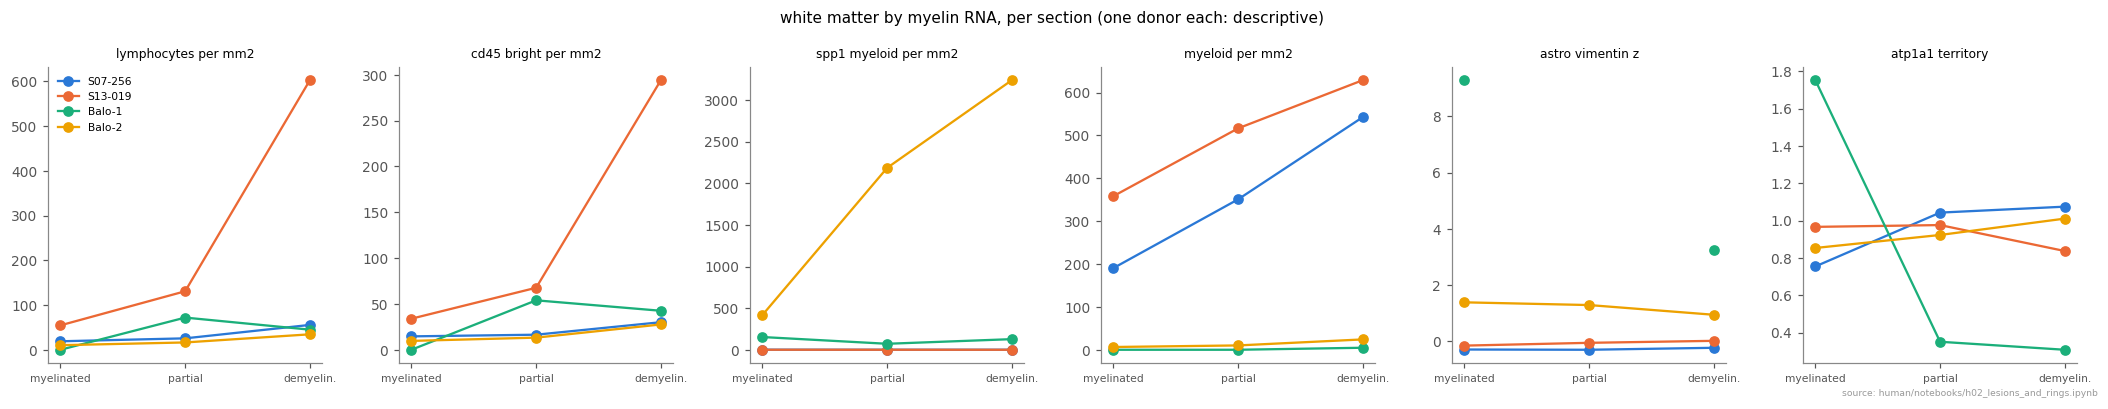

In [7]:
cols = ["lymphocytes_per_mm2", "cd45_bright_per_mm2", "spp1_myeloid_per_mm2", "myeloid_per_mm2", "astro_vimentin_z",
        "atp1a1_territory"]
fig, axs = plt.subplots(1, len(cols), figsize=(3.2 * len(cols), 3.6))
for ax, c in zip(axs, cols):
    for k, smp in enumerate(SAMPLES):
        t = zt[(zt["sample"] == smp) & zt.zone.isin(["myelinated", "partial", "demyelinated"])].set_index("zone")
        t = t.reindex(["myelinated", "partial", "demyelinated"])
        ax.plot(range(3), t[c], marker="o", color=plotting.CATEGORICAL[k], label=smp)
    ax.set_xticks(range(3), ["myelinated", "partial", "demyelin."], fontsize=7)
    ax.set_title(c.replace("_", " "), fontsize=8)
axs[0].legend(fontsize=7)
fig.suptitle("white matter by myelin RNA, per section (one donor each: descriptive)", fontsize=10)
fig.tight_layout()
plotting.save_fig(fig, "zones_by_section", OUT, SRC)

## Baló rings
In concentric sclerosis, bands of demyelinated and preserved myelin alternate. Profile: myelin RNA share and the
other readouts along a straight line through each Baló lesion (the line through the section's demyelinated centroid
along the direction of greatest variation of the myelin map), smoothed over 25 µm bins; all on one panel per section
so alternating bands line up.

Balo-1 Spearman with myelin RNA share along the line: {'astrocyte vimentin z': np.float64(0.53), 'ATP1A1 territory': np.float64(0.29), 'SPP1+ myeloid density': np.float64(-0.2), 'lymphocyte density': np.float64(0.08)}


Balo-2 Spearman with myelin RNA share along the line: {'astrocyte vimentin z': np.float64(0.22), 'ATP1A1 territory': np.float64(-0.32), 'SPP1+ myeloid density': np.float64(-0.58), 'lymphocyte density': np.float64(-0.23)}


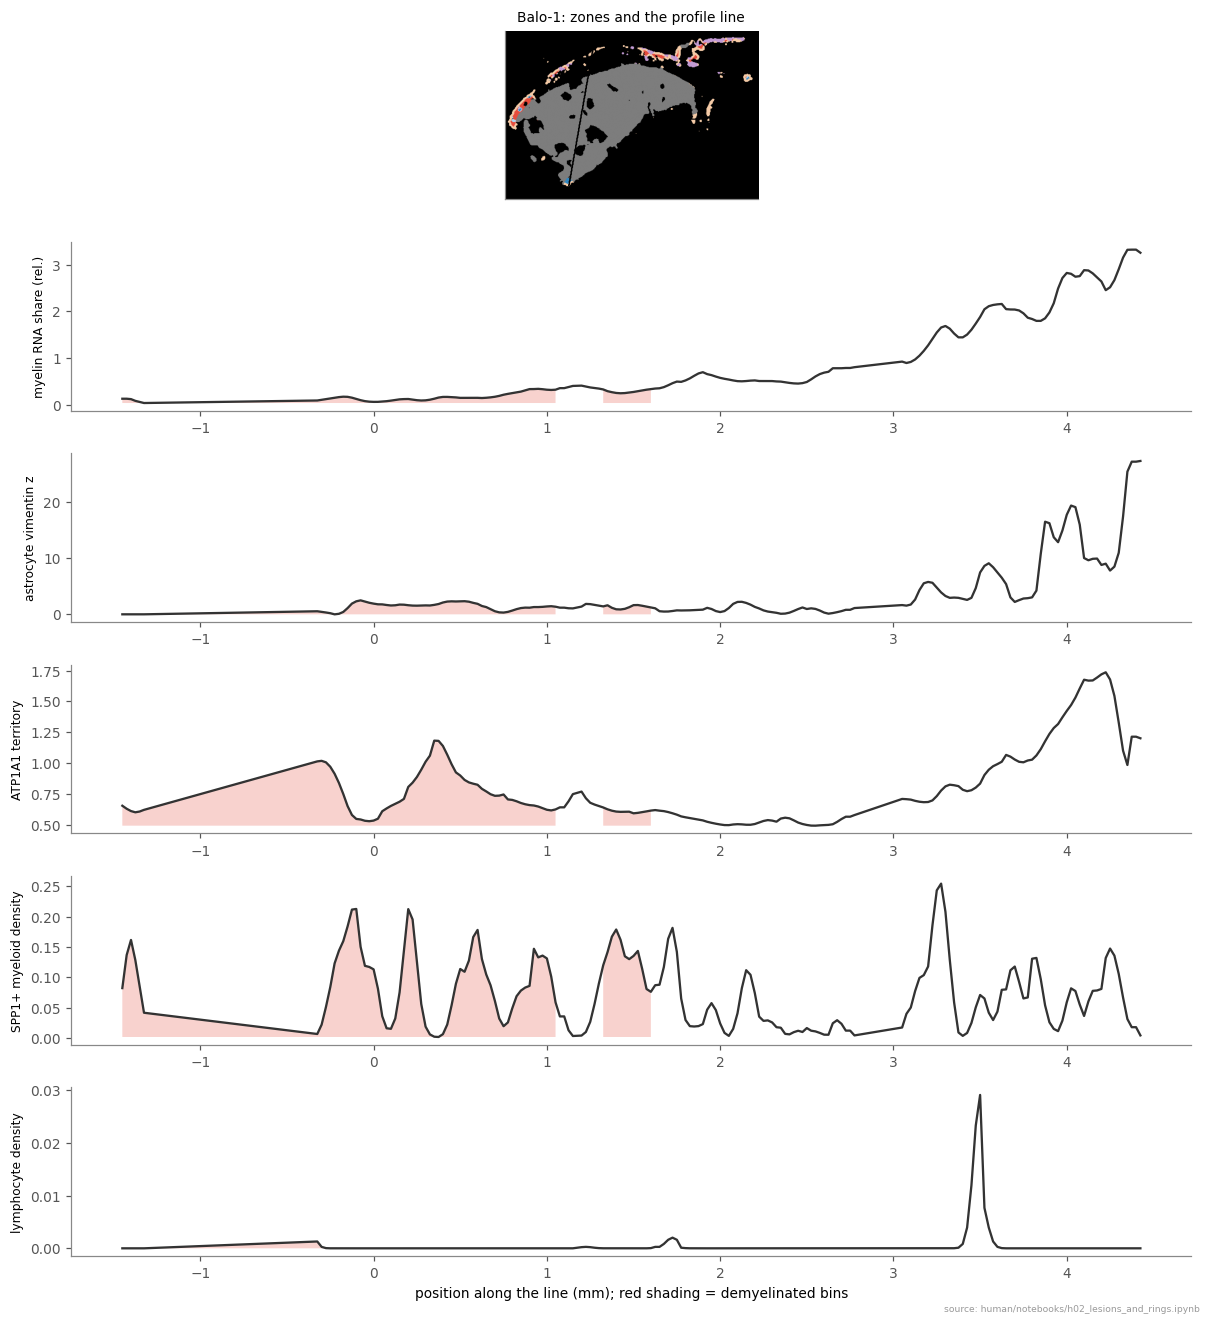

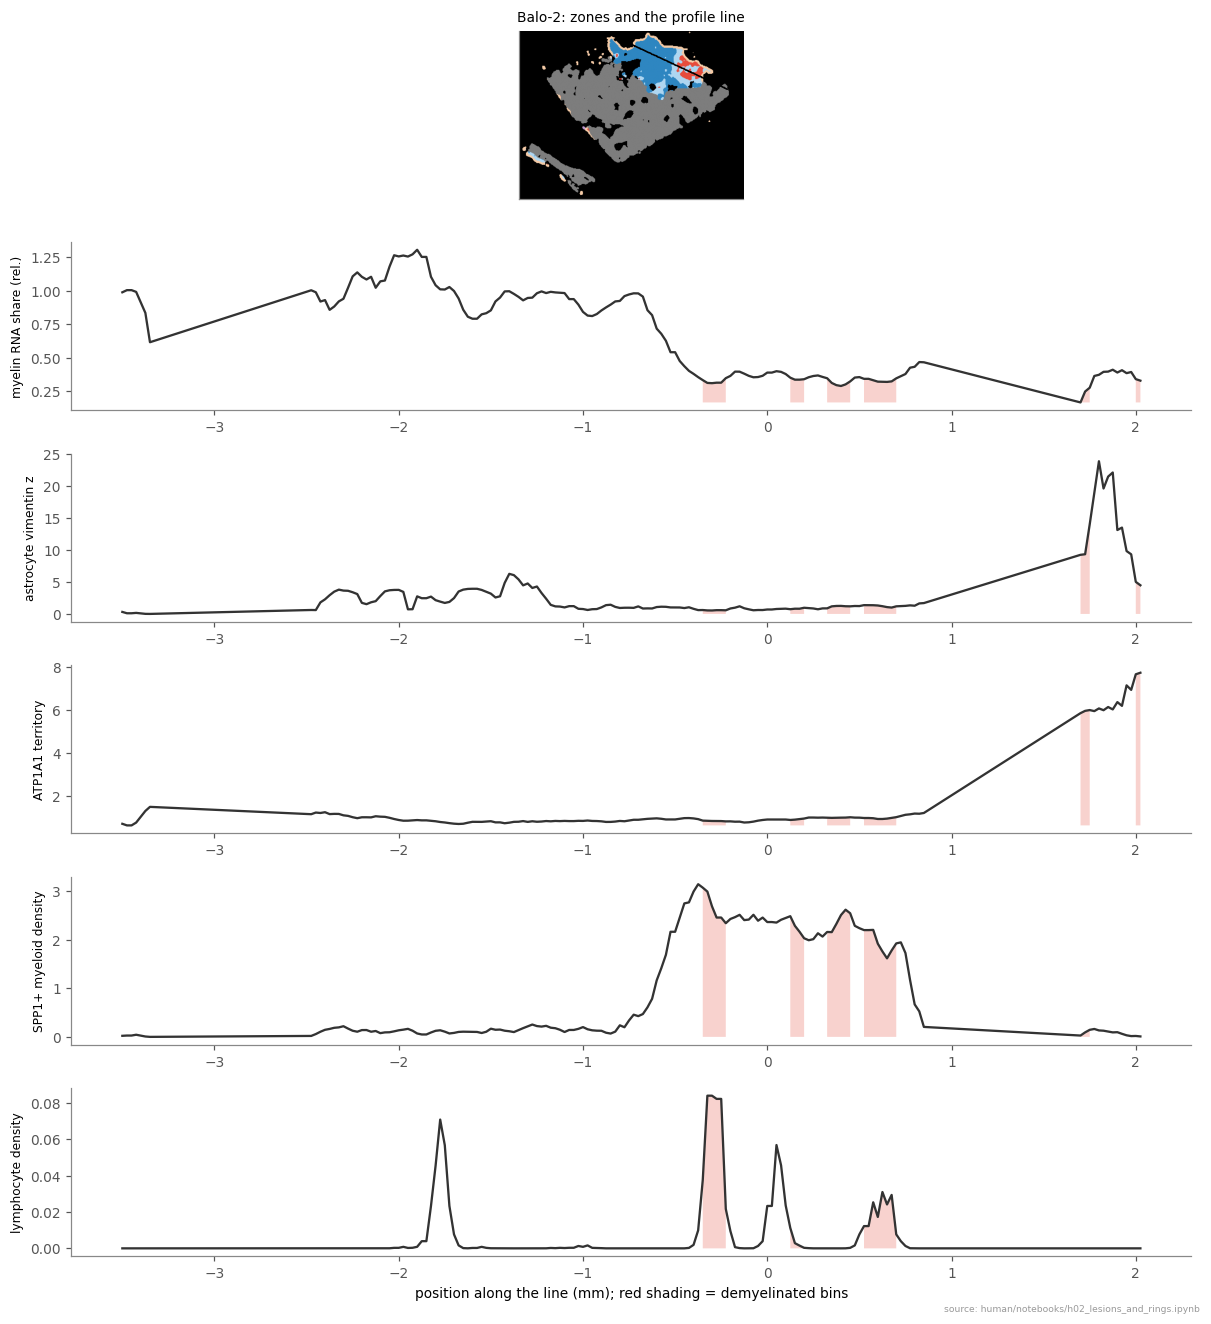

In [8]:
for smp in ["Balo-1", "Balo-2"]:
    z = Z[smp]
    ys, xs = np.where(z["zone"] == "demyelinated")
    if len(ys) < 20:
        continue
    cy, cx = ys.mean(), xs.mean()
    tissue = z["tissue"]
    rel = np.where(tissue, z["rel"], np.nan)
    best = None
    for ang in np.linspace(0, np.pi, 36, endpoint=False):
        t_ = np.arange(-400, 400)
        yy, xx = (cy + t_ * np.sin(ang)).astype(int), (cx + t_ * np.cos(ang)).astype(int)
        ok = (yy >= 0) & (yy < rel.shape[0]) & (xx >= 0) & (xx < rel.shape[1])
        v = rel[yy[ok], xx[ok]]
        v = v[np.isfinite(v)]
        if len(v) > 60 and (best is None or np.nanstd(v) > best[0]):
            best = (np.nanstd(v), ang)
    ang = best[1]
    t_ = np.arange(-400, 400)
    yy, xx = (cy + t_ * np.sin(ang)).astype(int), (cx + t_ * np.cos(ang)).astype(int)
    ok = (yy >= 0) & (yy < rel.shape[0]) & (xx >= 0) & (xx < rel.shape[1]) & tissue[np.clip(yy, 0, rel.shape[0] - 1),
                                                                                       np.clip(xx, 0, rel.shape[1] - 1)]
    yy, xx, t_ = yy[ok], xx[ok], t_[ok] * BIN
    prof = {"myelin RNA share (rel.)": rel[yy, xx]}
    for val, lab, msk in [("vim_z", "astrocyte vimentin z", d.cell_type.str.startswith("Astrocyte")),
                          ("atp_rel", "ATP1A1 territory", None)]:
        num, den = cell_grid(smp, msk, val)
        prof[lab] = (ndi.gaussian_filter(num, 1.5) / np.maximum(ndi.gaussian_filter(den, 1.5), 1e-3))[yy, xx]
    for t, lab in [(MYE_A, "SPP1+ myeloid density"), (LYMPH, "lymphocyte density")]:
        prof[lab] = ndi.gaussian_filter(cell_grid(smp, d.cell_type == t), 1.5)[yy, xx]
    fig, axs = plt.subplots(len(prof) + 1, 1, figsize=(11, 2.0 * (len(prof) + 1)), sharex=False)
    rgb = np.ones((*z["zone"].shape, 3))
    for k, c in ZCOLS.items():
        rgb[z["zone"] == k] = plt.matplotlib.colors.to_rgb(c)
    rgb[z["zone"] == ""] = 0
    axs[0].imshow(rgb, extent=(0, rgb.shape[1] * BIN, rgb.shape[0] * BIN, 0))
    axs[0].plot(xx * BIN, yy * BIN, color="black", lw=1)
    axs[0].set_title(f"{smp}: zones and the profile line", fontsize=9)
    axs[0].set_xticks([]); axs[0].set_yticks([])
    for ax, (lab, v) in zip(axs[1:], prof.items()):
        ax.plot(t_ / 1000, v, color="0.2")
        ax.fill_between(t_ / 1000, np.nanmin(v), v, where=prof["myelin RNA share (rel.)"] < 0.35, color="#e74c3c",
                        alpha=0.25, lw=0)
        ax.set_ylabel(lab, fontsize=8)
    axs[-1].set_xlabel("position along the line (mm); red shading = demyelinated bins")
    fig.tight_layout()
    plotting.save_fig(fig, f"rings_profile_{smp}", OUT, SRC)
    pr = pd.DataFrame(prof).dropna()
    print(smp, "Spearman with myelin RNA share along the line:",
          {k: round(pr[k].corr(pr["myelin RNA share (rel.)"], method="spearman"), 2) for k in pr.columns[1:]})

**Baló at 10 µm.** Myelin RNA share at 10 µm bins in a 3 mm window around each Baló section's main demyelinated
area, with SPP1+ myeloid cells on top: rings, if present, should show as alternating bands.

PosixPath('/Users/christoffer/work/karolinska/development/BeyondBoundaries/human/results/h02_lesions_and_rings/balo_myelin_10um.png')

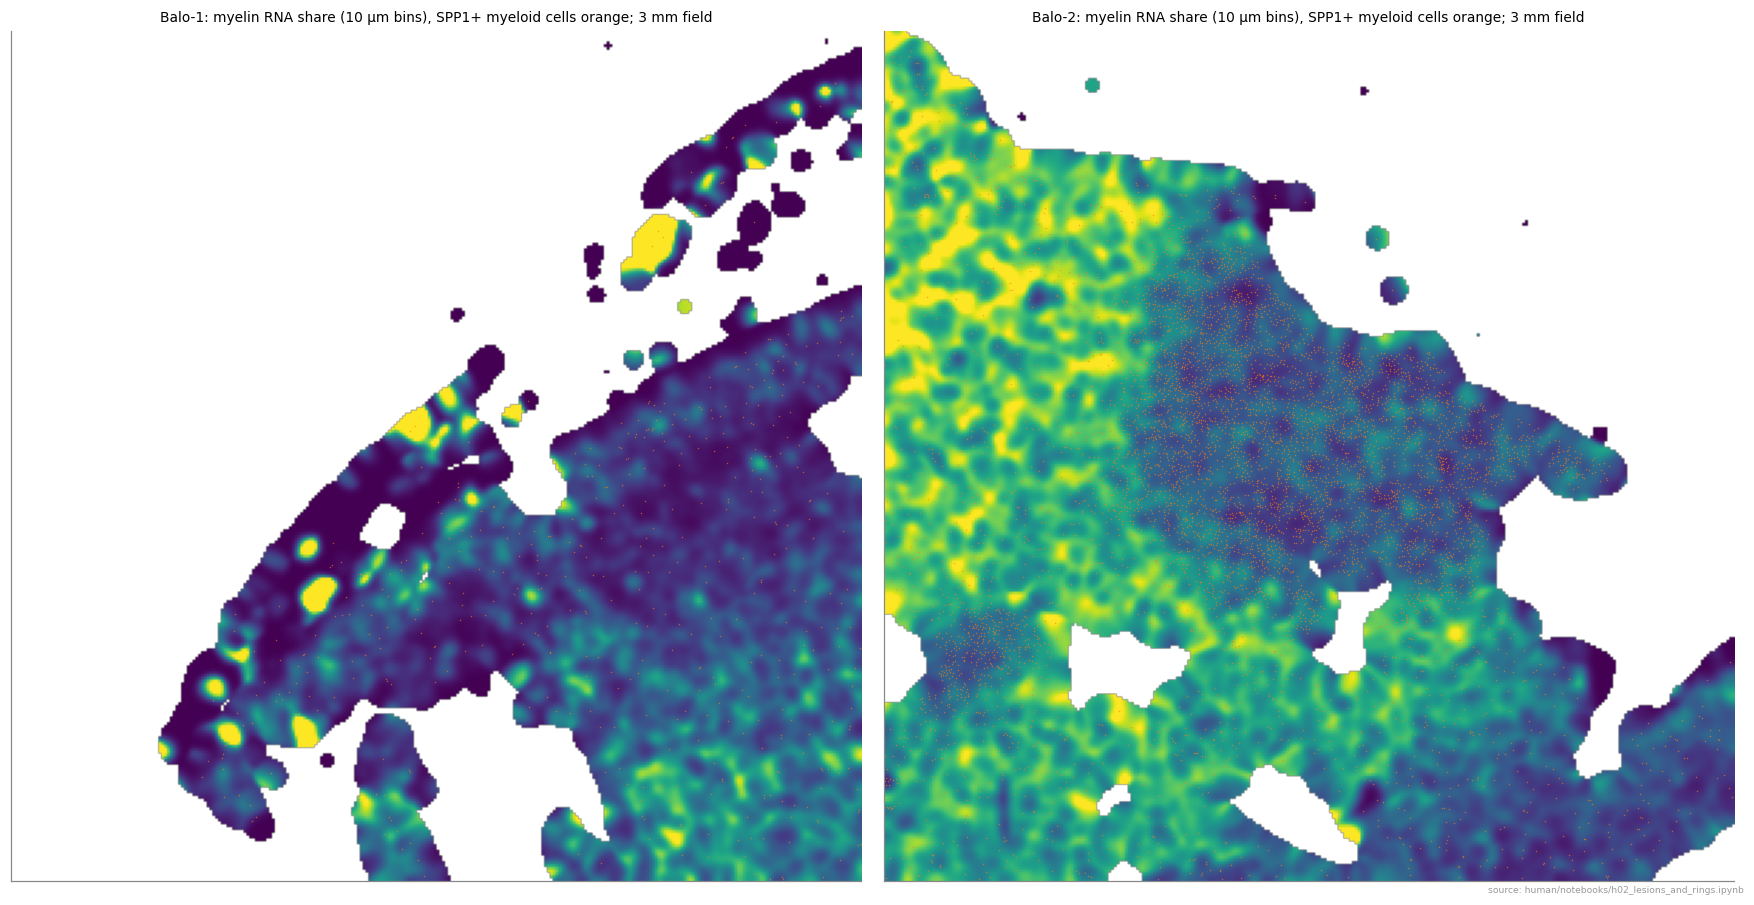

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(16, 8))
for ax, smp in zip(axs, ["Balo-1", "Balo-2"]):
    z = Z[smp]
    ys, xs = np.where(z["zone"] == "demyelinated")
    cy, cx = np.median(ys) * BIN, np.median(xs) * BIN
    half = 1500
    f = pq.ParquetFile(bundles[sec_of[smp]] / "transcripts.parquet")
    nb = int(2 * half / 10)
    allf, myf = np.zeros((nb, nb)), np.zeros((nb, nb))
    for i in range(f.num_row_groups):
        t = f.read_row_group(i, columns=["feature_name", "x_location", "y_location", "qv", "is_gene"])
        x, y = t["x_location"].to_numpy(), t["y_location"].to_numpy()
        m = (np.abs(x - cx) < half) & (np.abs(y - cy) < half) & (t["qv"].to_numpy() >= 20) & t["is_gene"].to_numpy()
        iy, ix = ((y[m] - cy + half) / 10).astype(int).clip(0, nb - 1), ((x[m] - cx + half) / 10).astype(int).clip(0, nb - 1)
        np.add.at(allf, (iy, ix), 1)
        mm = pc.is_in(t["feature_name"], value_set=pa.array(MYELIN)).to_numpy(zero_copy_only=False)[m]
        np.add.at(myf, (iy[mm], ix[mm]), 1)
    sh = ndi.gaussian_filter(myf, 2) / np.maximum(ndi.gaussian_filter(allf, 2), 0.5)
    sh[ndi.gaussian_filter(allf, 2) < 1] = np.nan
    ext_ = (cx - half, cx + half, cy + half, cy - half)
    ax.imshow(sh, cmap="viridis", vmax=np.nanpercentile(sh, 98), extent=ext_)
    c = d[(d.sample_id == smp) & (d.cell_type == MYE_A) & (np.abs(d.x_centroid - cx) < half) & (np.abs(d.y_centroid - cy) < half)]
    ax.scatter(c.x_centroid, c.y_centroid, s=1, c="#ff7f0e", lw=0, alpha=0.6)
    ax.set_title(f"{smp}: myelin RNA share (10 µm bins), SPP1+ myeloid cells orange; 3 mm field", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
plotting.save_fig(fig, "balo_myelin_10um", OUT, SRC)

## Findings
One donor per section: descriptions of each section, not tests across patients.

> **Lesions can be mapped from the RNA alone.** Myelin RNA share at 25 µm resolves the grey-matter butterfly (neuron
> density), myelinated white matter and demyelinated white matter; in S07-256 a broad demyelinated band runs through
> the outer white matter under the meninges (the subpial pattern typical of MS spinal cord), in S13-019 smaller
> demyelinated areas.
>
> **Lymphocytes, most of them CD45-bright, gather in demyelinated white matter and the meninges.** S13-019: 602
> lymphocytes/mm² in demyelinated vs 55 in myelinated white matter (11×), meninges 198, subpial rim 235; S07-256: 56
> vs 19 (3×), meninges 73. 49–77 % of lymphocytes are CD45-bright in every zone, so the stain marks immune cells in
> lesions and meninges alike. Myeloid cells also rise with demyelination (S07-256 191 → 543/mm²; S13-019 358 → 629).
>
> **Astrocyte vimentin:** slightly higher in demyelinated than in myelinated white matter (S07-256 −0.29 → −0.23,
> S13-019 −0.15 → +0.02 z) and highest in the subpial rim (glia limitans; S13-019 +2.98), as in mouse.
>
> **ATP1A1: not interpretable across zones here.** In S07-256 the boundary channel is much brighter in the lower
> half of the section than in the upper half, with a step at the horizontal crack: an imaging/staining difference
> that a section-wide normalisation does not remove. Zone comparisons need a local correction first.
>
> **Baló: an active lesion edge, no concentric rings in these sections.** Balo-2 has a sharp boundary between
> myelinated tissue and a demyelinated area packed with SPP1+ activated myeloid cells (3,240/mm² vs 417 in
> myelinated tissue), astrocyte vimentin high around it. At 10 µm no alternating myelin bands are visible in either
> section; Balo-1 is mostly demyelinated. Much of both sections is grey matter (cortex), and ~6 % is out of focus.
> The H&E of these sections shows no rings either (confirmed 2026-10-14): the sampled tissue holds no concentric
> lesion, so a ring analysis needs other Baló material.